```{contents}
:local:
:depth: 2
```

# 3.2 Direct-Search Methods

:::{admonition} Draft status: first draft
:class: warning
First draft (2026-10-30), written from the course design notes. Not yet reviewed.
:::

```{admonition} Lectures
:class: tip
This topic accompanies these recorded lessons:

- Module 6, Lesson 4: *Direct-Search Methods*
- Module 7, Lesson 1: *Local Direct-Search*
- Module 7, Lesson 2: *Positive Spanning Sets*
- Module 7, Lesson 3: *Convergence in Sampling-Based Optimization*
```

:::{admonition} Learning Objectives
:class: tip

By the end of this topic, you should be able to:

- Run compass search by hand on a one-dimensional black box and explain each step.
- Name the three mechanisms of local direct search (descent, geometry, step size to zero) and contrast pattern search with simplex-based search.
- Define a positive spanning set and a positive basis, compute the cosine measure of a set of directions, and state why a positive spanning set must contain a descent direction.
- State the bound that links the gradient to the step size after an unsuccessful poll, and explain what it guarantees and what it does not.
- Run compass search and Nelder–Mead on the electrolyzer black boxes and interpret their success rates.
:::

A direct-search method uses nothing but comparisons of function values: it evaluates the black box at a few points, keeps the best, and decides where to look next. It fits no model, estimates no gradient, and assumes nothing about the shape of $f$. This makes direct search the most basic family of data-driven methods, and also the easiest to reason about: everything it knows is in the list of points it has sampled.

This topic builds direct search up from one dimension, explains why the simple idea works at all, and then runs the two classic local methods, compass search and Nelder–Mead, on the electrolyzer black boxes of {doc}`Topic3.1-Optimization_without_Equations`.

## Direct search in one dimension

Suppose we can only evaluate BB1, the cost of two type-A stacks sharing 180 kg/h as a function of the first stack's load $x_1$. A direct-search method needs three things: a **starting point**, an initial **step size**, and a **rule** for moving and for changing the step. The simplest rule is the one used by Fermi and Metropolis on one of the first digital computers, as Kolda, Lewis and Torczon (2003) recount: vary one parameter at a time by a fixed step; if no step improves the fit, halve the step and try again; stop when the step is small enough. In one dimension this is **compass search**:

1. At the current point $x$ with step $\alpha$, evaluate $f(x + \alpha)$. If it is lower than $f(x)$, move there and repeat.
2. Otherwise evaluate $f(x - \alpha)$. If it is lower, move there and repeat.
3. If neither is lower, the step was unsuccessful: halve $\alpha$.
4. Stop when $\alpha$ falls below a tolerance.

The cell below runs this by hand on BB1 from two starting points, one in the wide middle well and one in the narrow edge well, using an initial step of 0.1 (18 kg/h) and a stopping tolerance of 0.01, and it prints every evaluation so we can follow each line on paper.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('../settings/plot_style.mplstyle')
from scipy.optimize import minimize, Bounds
from _lib import electrolyzer as el
from _lib.part3a_tools import Counter

def compass_1d(f, x, step=0.1, tol=0.01, lo=0.0, hi=0.9, verbose=True):
    fx = f([x])
    while step > tol:
        for d in (+1, -1):
            y = min(max(x + d * step, lo), hi)
            fy = f([y])
            better = fy < fx - 1e-12
            if verbose:
                print(f"  x = {x:.4f}  step {step:.4f}  try {y:.4f}: f = {fy:.4f} {'< ' if better else '>='} {fx:.4f}"
                      f"{'  move' if better else ''}")
            if better:
                x, fx = y, fy
                break
        else:
            step /= 2                         # both directions failed: halve the step
    return x, fx

for x0 in (0.6, 0.04):
    f = Counter(el.bb1)
    print(f"start x1 = {x0}")
    x, fx = compass_1d(f, x0)
    print(f"  stop at x1 = {x:.4f}, f = {fx:.5f}, after {f.n} evaluations\n")

start x1 = 0.6
  x = 0.6000  step 0.1000  try 0.7000: f = 1.6850 >= 1.6591
  x = 0.6000  step 0.1000  try 0.5000: f = 1.6444 <  1.6591  move
  x = 0.5000  step 0.1000  try 0.6000: f = 1.6591 >= 1.6444
  x = 0.5000  step 0.1000  try 0.4000: f = 1.6444 >= 1.6444
  x = 0.5000  step 0.0500  try 0.5500: f = 1.6500 >= 1.6444
  x = 0.5000  step 0.0500  try 0.4500: f = 1.6425 <  1.6444  move
  x = 0.4500  step 0.0500  try 0.5000: f = 1.6444 >= 1.6425
  x = 0.4500  step 0.0500  try 0.4000: f = 1.6444 >= 1.6425
  x = 0.4500  step 0.0250  try 0.4750: f = 1.6430 >= 1.6425
  x = 0.4500  step 0.0250  try 0.4250: f = 1.6430 >= 1.6425
  x = 0.4500  step 0.0125  try 0.4625: f = 1.6426 >= 1.6425
  x = 0.4500  step 0.0125  try 0.4375: f = 1.6426 >= 1.6425
  stop at x1 = 0.4500, f = 1.64250, after 13 evaluations

start x1 = 0.04
  x = 0.0400  step 0.1000  try 0.1400: f = 1.7011 >= 1.6874
  x = 0.0400  step 0.1000  try 0.0000: f = 1.5892 <  1.6874  move
  x = 0.0000  step 0.1000  try 0.1000: f = 1.7074 >= 

Starting from $x_1 = 0.6$, the search steps down to 0.5 and fails in both directions, so it halves the step and steps to 0.45, and then it fails at every smaller step until it stops at the equal split, 1.6425, after 13 evaluations. Starting from $x_1 = 0.04$, the step toward the middle fails but the step toward the edge succeeds, and the search lands on $x_1 = 0$, which is the global optimum 1.58921, after 11 evaluations, although most of these are spent confirming that nothing nearby is better.

In both runs the method did exactly what it promises, since each one found a point which no nearby step improves, but the point it found was decided by where it started. Like the local NLP solver of Topic 2.6, a local direct-search method finds the well it starts in. The initial step also matters, because a large step can jump over a hill into a different well (for better or worse), so we need to treat the starting step as a real tuning choice rather than a detail.

Halving on failure is only one possible rule. In the in-class exercise of the lectures we are asked for a loop which uses nothing but function values and a step size that may change every iteration, and a natural answer also *grows* the step after a success: try $x + \alpha$, and if it is better, move there and multiply $\alpha$ by 1.5, but if not, stay, reverse the direction and halve the step ($\alpha \leftarrow -\alpha/2$). Growing the step makes the search cheaper when it is far from a minimum, and it also makes it more likely to jump a hill. The cell below runs this rule on BB1 from $x_1 = 0.75$, which is in the middle well near the right-hand hill, first stepping right and then stepping left.

In [2]:
def expanding_1d(f, x, step=0.1, tol=0.01, lo=0.0, hi=0.9):
    fx = f([x])
    while abs(step) > tol:
        y = min(max(x + step, lo), hi); fy = f([y])
        if fy < fx - 1e-12:
            x, fx = y, fy; step *= 1.5           # success: move and grow the step
        else:
            step *= -0.5                         # failure: reverse and halve
    return x, fx

for s0 in (+0.1, -0.1):
    f = Counter(el.bb1)
    x, fx = expanding_1d(f, 0.75, step=s0)
    print(f"start 0.75, first step {s0:+.1f}: stop at x1 = {x:.4f}, f = {fx:.5f}, {f.n} evaluations")

start 0.75, first step +0.1: stop at x1 = 0.9000, f = 1.58921, 8 evaluations
start 0.75, first step -0.1: stop at x1 = 0.4543, f = 1.64251, 11 evaluations


When it steps right, the growing step carries the search over the hill at $x_1 \approx 0.807$ and onto the edge, which is the global optimum, in 8 evaluations, but when it steps left it slides into the equal-split trap in 11. The start and the rule were the same in both cases, so only the first direction differed, and with it the answer. The expanding rule is a heuristic, since it has no geometry guarantee beyond the one which the next sections give to any method that polls a positive spanning set and shrinks its step on failure.

:::{exercise}
:label: ex-t32-hand

Run `compass_1d` on BB1 from $x_1 = 0.06$, which is also in the edge well. Where does it stop, and why? Repeat with an initial step of 0.02. Then find, by trying starting points on a grid, the set of starts from which the step-0.1 search reaches the global optimum. How does it compare with the width of the edge wells?
:::

## Local direct search: three mechanisms

In more than one dimension, "step left or right" becomes "step along each of a set of directions". Every convergent local direct-search method rests on three mechanisms, and we will name these before we build one.

1. **Descent.** The method must be able to find a direction in which $f$ decreases, using samples alone, and it accepts a step only if the step lowers $f$.
2. **Geometry.** The sample points around the current point must be arranged so that a descent direction, if one exists, cannot be missed; directions bunched together on one side of the point would leave whole half-spaces unexplored.
3. **Step size to zero.** When no sample improves on the current point, the step size shrinks, and as it goes to zero the samples crowd around the current point, and the final answer can be made as accurate as we like.

There are two families which implement these mechanisms in different ways. **Pattern-search** (or directional direct-search) methods sample along a fixed set of directions, called the **pattern**, and move to a better sample, and compass search, which uses the coordinate directions $\pm e_i$, is the simplest example; in these methods the geometry is controlled by choosing the pattern well, which is the subject of the next section. **Simplex methods**, of which Nelder–Mead is the best known, keep $n+1$ points in $n$ dimensions and move away from the worst one, and their geometry is controlled (when it is controlled at all) by keeping the simplex from collapsing flat.

A **simplex** in $\mathbb{R}^n$ is the convex hull of $n+1$ points which do not all lie in a common hyperplane, so it is a line segment in one dimension, a triangle in two, and a tetrahedron in three. (The **convex hull** of a set of points is the smallest convex set which contains them.) The Nelder–Mead method (Nelder and Mead 1965; not related to the simplex method for LPs of Topic 1.5) works on a simplex of trial points, and at each iteration it ranks the vertices by $f$ and tries to replace the worst one:

- **reflect** the worst vertex through the centroid of the others;
- if the reflected point is the best so far, **expand** further in the same direction;
- if it is poor, **contract** back toward the centroid;
- if even that fails, **shrink** the whole simplex toward the best vertex.

Nelder–Mead adapts its shape to the landscape and is often fast on smooth problems with few variables, which is why it is the default derivative-free method in MATLAB and a standard option in `scipy.optimize.minimize`. But it has no convergence guarantee. McKinnon (1998) gave a smooth, strictly convex function in two dimensions on which Nelder–Mead converges to a point that is not stationary, because the simplex collapses flat. Pattern search can be proven to converge, under the conditions of the next two sections, at the price of more samples. The course notebook demonstrates scipy's Nelder–Mead on the Rosenbrock function, the classic curved-valley test problem. Other members of the family include **implicit filtering**, which estimates a "simplex gradient" from the vertices of a simplex and steps along its negative, and the trust-region methods of Topic 3.6, which follow the same steps but move by a fitted model.

Local direct search suits problems where designed experiments can be run at chosen points, each evaluation is reasonably cheap (seconds to minutes rather than hours), the number of variables is modest, and convergence to a stationary point is what matters. Parallel computing helps, because the points of one poll can be evaluated at the same time. It is the wrong tool when the equations are available (the field's own advice, as Conn et al. 2009 put it in their introduction, is that if clean derivatives can be obtained, even with considerable effort, and the function is smooth and noise-free, derivative-free methods should not be used), and for large problems with many discrete decisions, where the landscape is broken into pieces that no local step can connect (Topic 3.4 shows this on BB3).

The figure below runs both methods on BB2 from the same start, $(x_A, x_B) = (0.3, 0.5)$, and draws the points evaluated by each one.

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


Nelder-Mead: (0.374, 0.582), f = 2.2291, 83 evaluations
compass:     (0.000, 0.812), f = 2.0901, 97 evaluations
global optimum of BB2: 2.0818 at (0.702, 0)


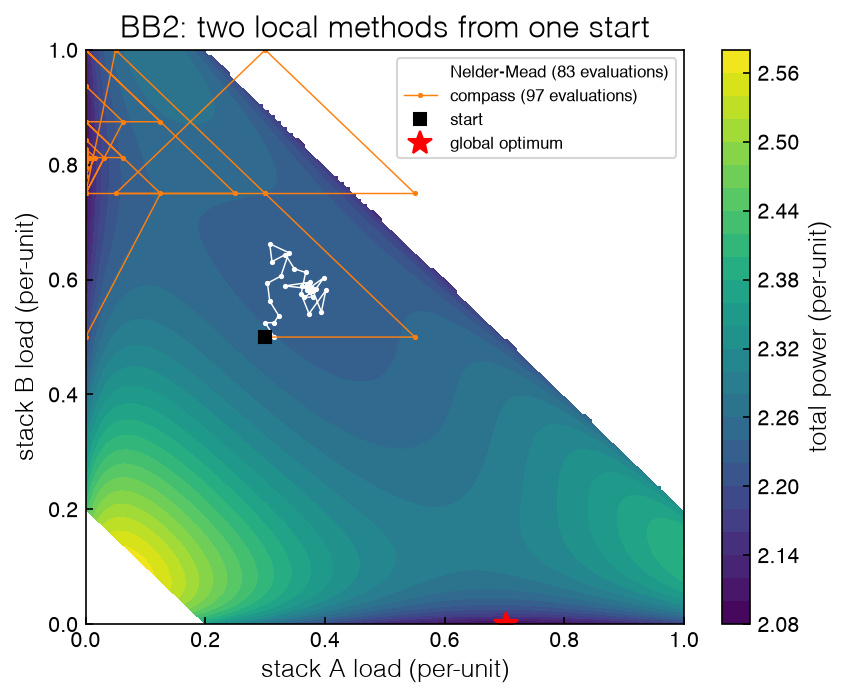

In [3]:
from _lib.part3a_tools import compass

class Recorder(Counter):
    """A Counter that also keeps the points it was asked about."""
    def __init__(self, f):
        super().__init__(f); self.points = []
    def __call__(self, x):
        self.points.append(np.array(x, float).copy()); return super().__call__(x)

lo, hi, x0 = np.zeros(2), np.ones(2), np.array([0.3, 0.5])
nm, cs = Recorder(el.bb2), Recorder(el.bb2)
r_nm = minimize(nm, x0, method='Nelder-Mead', bounds=Bounds(lo, hi), options={'xatol': 1e-6, 'fatol': 1e-8})
x_cs, f_cs = compass(cs, x0, lo, hi)

g = np.linspace(0, 1, 201)
F2 = np.array([[el.bb2([a, b]) for a in g] for b in g])
fig, ax = plt.subplots(figsize=(6, 5))
c = ax.contourf(g, g, np.ma.masked_where(F2 >= el.PENALTY, F2), levels=25, cmap='viridis')
fig.colorbar(c, label='total power (per-unit)')
for rec, lab, col in ((nm, 'Nelder-Mead', 'w'), (cs, 'compass', 'tab:orange')):
    P = np.array(rec.points)
    ax.plot(P[:, 0], P[:, 1], '.-', color=col, ms=3, lw=0.7, label=f'{lab} ({rec.n} evaluations)')
ax.plot(*x0, 'ks', label='start')
ax.plot(0.702, 0.0, 'r*', ms=12, label='global optimum')
ax.set_xlabel('stack A load (per-unit)'); ax.set_ylabel('stack B load (per-unit)')
ax.set_title('BB2: two local methods from one start'); ax.legend(fontsize=8, loc='upper right')
print(f"Nelder-Mead: ({r_nm.x[0]:.3f}, {r_nm.x[1]:.3f}), f = {r_nm.fun:.4f}, {nm.n} evaluations")
print(f"compass:     ({x_cs[0]:.3f}, {x_cs[1]:.3f}), f = {f_cs:.4f}, {cs.n} evaluations")
print(f"global optimum of BB2: 2.0818 at (0.702, 0)")

Even though they start from the same point, the two methods end in different places, and neither of them finds the global optimum. Nelder–Mead settles at an interior point where each of the three stacks is on, (0.374, 0.582), with a cost of 2.2291, while compass search walks to the edge $x_A = 0$ and stops at (0, 0.812) with stack A off and a cost of 2.0901, which is the best B + C split. The global optimum, A + C with B off at 2.0818, is a third well. Each method found a local minimum, and its internal rules chose which one.

:::{exercise}
:label: ex-t32-nm-steps

Rerun Nelder–Mead on BB2 from the same start with a larger initial simplex, `options={'initial_simplex': [[0.3, 0.5], [0.9, 0.5], [0.3, 0.05]]}`. Does it end in a different well? Use the `callback` argument of `minimize` to record the best vertex at each iteration, plot that path on the contour map, and identify where the simplex expands and where it contracts or shrinks.
:::

## Positive spanning sets and the cosine measure

:::{admonition} Adapted from the course notebook
:class: note
The definitions of positive spans, positive spanning sets and positive bases, their two-dimensional examples, and the simplex and Nelder–Mead material in this topic are adapted from the course notebook `Intro to Derivative-Free Optimization (Module6-7).ipynb` (MIT License, © 2022 Data-Driven PSE Lab @ChBE-GT). The electrolyzer black boxes replace the notebook's test functions, and the cosine-measure computations are new.
:::

Why does compass search work at all? The reason is that the compass directions $\pm e_1, \pm e_2$ are chosen so that wherever the downhill direction points, at least one of them points roughly the same way. This property is called positive spanning, which is what gives us the one precise result of this topic.

We will need some definitions first. The **linear span** of a set of vectors is the smallest linear subspace containing them (i.e. the set of all their linear combinations). The **positive span** of a set of vectors $D = \{d_1, \ldots, d_r\}$ in $\mathbb{R}^n$ is the set of their nonnegative combinations, which is the convex cone

$$
\mathrm{pspan}(D) = \{\, v \in \mathbb{R}^n : v = a_1 d_1 + \cdots + a_r d_r,\ a_i \ge 0 \,\}.
$$

A set is called a **positive spanning set** if its positive span is all of $\mathbb{R}^n$. A set is **positively dependent** if one of its vectors can be written as a nonnegative combination of the others, and otherwise it is **positively independent**. If a positive spanning set is also positively independent we call it a **positive basis**, and a positive basis of $\mathbb{R}^n$ has between $n+1$ vectors (a **minimal** positive basis) and $2n$ vectors (a **maximal** one). In $\mathbb{R}^2$ the compass directions $\{e_1, e_2, -e_1, -e_2\}$ are a maximal positive basis, and $\{e_1, e_2, -(e_1+e_2)/\sqrt{2}\}$ is a minimal one. Note the difference from an ordinary basis: $\{e_1, e_2\}$ spans $\mathbb{R}^2$ linearly but its positive span is only the first quadrant.

We call a vector $d$ a **descent direction** for $f$ at $x$ if some step $\alpha > 0$ gives $f(x + \alpha d) < f(x)$. If $f$ is continuously differentiable, then every $d$ with $-\nabla f(x)^\top d > 0$ (i.e. every direction at an acute angle to the negative gradient) is a descent direction.

**The descent property.** $D$ is a positive spanning set if and only if, for every nonzero vector $v$, some $d \in D$ satisfies $v^\top d > 0$. If we apply this with $v = -\nabla f(x)$ at a point where the gradient is not zero, then some direction in $D$ makes an acute angle with the negative gradient, so it is a **descent direction**, and $f(x + \alpha d) < f(x)$ for every small enough step $\alpha > 0$. This means a pattern which positively spans the space cannot miss a way downhill. On the other hand, a set which does not positively span the space leaves some cone of directions uncovered, and if the negative gradient points into that cone, the method will shrink its step forever at a point which is not stationary.

**The cosine measure.** The descent property says that a good direction exists, and the **cosine measure** says how good it is guaranteed to be:

$$
\kappa(D) = \min_{v \ne 0}\ \max_{d \in D}\ \frac{v^\top d}{\|v\|\,\|d\|}.
$$

For every vector $v$, some direction in $D$ makes an angle with $v$ whose cosine is at least $\kappa(D)$. $D$ is a positive spanning set exactly when $\kappa(D) > 0$, and the larger $\kappa(D)$ is, the better the worst-case direction. For the compass directions in $\mathbb{R}^n$ we have $\kappa = 1/\sqrt{n}$, and in one dimension $D = \{+1, -1\}$ and $\kappa = 1$.

**What an unsuccessful poll tells us.** Suppose that the gradient of $f$ is Lipschitz continuous with constant $M$, meaning that $\|\nabla f(y) - \nabla f(x)\| \le M \|y - x\|$ for all $x$ and $y$ near the current point, and so $M$ is a measure of how quickly the slope can change. (Lipschitz continuity is stated for $f$ itself in Topic 3.3, where it is the source of the bound used by DIRECT.) Now suppose that a poll is **unsuccessful**, i.e. $f(x + \alpha d) \ge f(x)$ for every $d \in D$. Then

$$
\|\nabla f(x)\| \;\le\; \frac{M}{2\,\kappa(D)}\ \alpha \max_{d \in D} \|d\|.
$$

The proof is only three lines long. By Taylor's theorem with the Lipschitz bound, $f(x + \alpha d) - f(x) \le \alpha \nabla f(x)^\top d + \tfrac{M}{2}\alpha^2 \|d\|^2$. Since the poll was a failure, the left side is nonnegative, and therefore $-\nabla f(x)^\top d \le \tfrac{M}{2}\alpha\|d\|^2$ for every $d$. Taking the $d$ making the cosine measure's angle with $-\nabla f(x)$, so that $-\nabla f(x)^\top d \ge \kappa(D)\|\nabla f(x)\|\,\|d\|$, and dividing by $\kappa(D)\|d\|$ then gives the bound (Kolda et al. 2003; Conn et al. 2009, chapter 2).

This bound is the reason why pattern search converges, since for every failed poll the gradient at the current point can be at most a constant times the step size. The step is halved after every failure, so for a method that keeps failing $\alpha \to 0$, and with it $\|\nabla f\| \to 0$, and therefore the iterates will approach a stationary point. The constant is set by two quantities: $M$ is a measure of the nonlinearity of the function, and $1/\kappa(D)$ is a measure of the geometry of the pattern, so a pattern with a small cosine measure gives a weak guarantee at any step size. If $\Delta = \alpha \max_{d}\|d\|$ is the radius of the poll, the bound can be written as $\|\nabla f(x)\| \le \kappa_{eg}\,\Delta$ with $\kappa_{eg} = M/(2\kappa(D))$, which is the form used in the lectures. And since a nonzero gradient guarantees that some small enough step succeeds, a search started away from a stationary point needs only finitely many step reductions before there is another improvement, so the search is systematic and not random. The bound also has limits, and it helps to see what it does not say. The bound only guarantees a stationary point, not a global minimum, and the compass search stopping at the equal split of BB1 satisfied it perfectly. It also needs a smooth gradient, and BB3 does not have one because of its on/off switches and penalty jumps.

The next cell computes the cosine measure of four sets in $\mathbb{R}^2$ by brute force over directions $v$, and draws them. The last set, $\{e_1, e_2, (-1, -\delta)\}$, is a positive basis for every $\delta > 0$, but as $\delta \to 0$ its third vector swings toward $-e_1$, so the direction $(0, -1)$ is barely covered by the set.

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


maximal basis \pm e_1, \pm e_2         kappa = 0.7071
minimal basis                          kappa = 0.3827
spanning set, not a basis              kappa = 0.3827
minimal basis, \delta = 0.1            kappa = 0.0498
delta =  0.50: kappa = 0.2298, formula cos((pi - theta)/2) = 0.2298
delta =  0.10: kappa = 0.0498, formula cos((pi - theta)/2) = 0.0498
delta =  0.01: kappa = 0.0050, formula cos((pi - theta)/2) = 0.0050


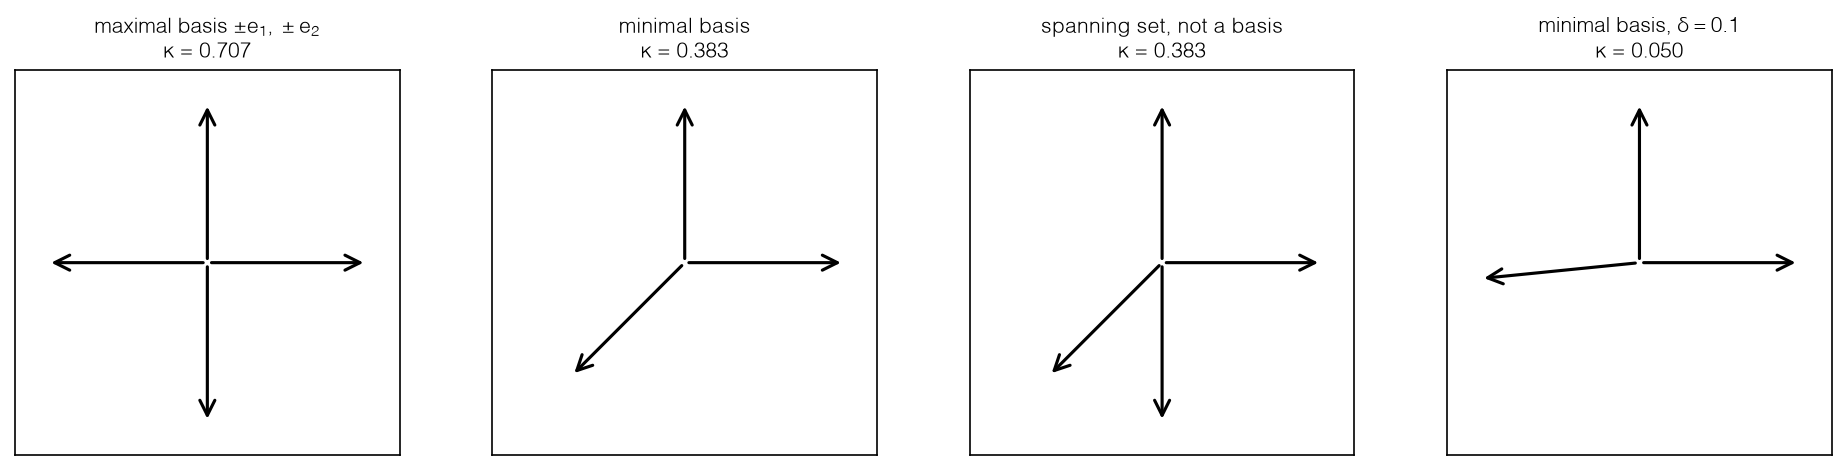

In [4]:
from _lib.part3a_tools import cosine_measure

s = np.sqrt(2) / 2
sets = {
    'maximal basis $\\pm e_1, \\pm e_2$': [[1, 0, -1, 0], [0, 1, 0, -1]],
    'minimal basis': [[1, 0, -s], [0, 1, -s]],
    'spanning set, not a basis': [[1, 0, -s, 0], [0, 1, -s, -1]],
    'minimal basis, $\\delta = 0.1$': [[1, 0, -1], [0, 1, -0.1]],
}
fig, ax = plt.subplots(1, 4, figsize=(13, 3.3))
for a, (name, D) in zip(ax, sets.items()):
    D = np.array(D, float)
    for d in D.T:
        a.annotate('', xy=d / np.linalg.norm(d), xytext=(0, 0), arrowprops=dict(arrowstyle='->', lw=1.5))
    k = cosine_measure(D)
    a.set_title(f'{name}\n$\\kappa$ = {k:.3f}', fontsize=10)
    a.set_xlim(-1.2, 1.2); a.set_ylim(-1.2, 1.2); a.set_aspect('equal'); a.set_xticks([]); a.set_yticks([])
    print(f"{name.replace(chr(36), ''):38s} kappa = {k:.4f}")
plt.tight_layout()
for delta in (0.5, 0.1, 0.01):
    theta = np.arctan(delta)                     # third vector = -(cos theta, sin theta), up to scale
    print(f"delta = {delta:5.2f}: kappa = {cosine_measure([[1, 0, -1], [0, 1, -delta]]):.4f}, "
          f"formula cos((pi - theta)/2) = {np.cos((np.pi - theta) / 2):.4f}")

The maximal basis has $\kappa = 0.707 = 1/\sqrt{2}$, so every direction is within 45° of a pattern direction. The minimal basis saves one evaluation per poll, but the price is $\kappa = 0.383$, which is a worst-case angle of 67.5°. Adding the vector $-e_2$ to the minimal basis gives a positive spanning set that is not a basis, but it does not improve the cosine measure at all ($\kappa$ stays 0.383) because the worst-covered direction is somewhere else. The skewed basis shows how the guarantee degrades, with $\kappa$ = 0.230, 0.050 and 0.005 for $\delta$ = 0.5, 0.1 and 0.01; the set still positively spans the plane, but the bound on the gradient at an unsuccessful poll grows as $1/\kappa$. For this family it is also possible to write a closed form, since with third vector $-(\cos\theta, \sin\theta)$ and $0 < \theta \le \pi/4$ the cosine measure is $\kappa = \cos\big((\pi - \theta)/2\big)$, which is confirmed by the cell ($\theta = \pi/4$ gives the minimal basis's 0.383).

Positive bases are also important beyond the descent property, because the same sample geometry keeps the linear and quadratic models of the model-based methods in Topic 3.6 well conditioned. This is because points spread around the current point in all directions do not produce the nearly singular systems produced by clustered points.

:::{exercise}
:label: ex-t32-cosine

Compute the cosine measure of the compass directions $\pm e_i$ in $\mathbb{R}^2$, $\mathbb{R}^3$ and $\mathbb{R}^4$ (extend `cosine_measure` to $n$ dimensions by sampling $v$ from random unit vectors), and compare with $1/\sqrt{n}$. Then find a minimal positive basis of $\mathbb{R}^2$ with the largest possible cosine measure. (Hint: think of an equilateral triangle.) How many evaluations per poll does each choice cost in $\mathbb{R}^{10}$?
:::

## The pattern-search algorithm

Putting the pieces together, we can get a generic and provably convergent pattern-search method, in the form presented in Conn, Scheinberg and Vicente (2009, chapter 7), with three steps in each iteration.

1. **Search step (optional).** Evaluate $f$ at any finite set of points chosen by any rule at all: a few random points, the minimum of a surrogate model, a guess from experience. If one improves on the current point, move there and skip the poll. This step is where heuristics and models enter without spoiling the theory.
2. **Poll step.** Evaluate $f(x + \alpha d)$ for the directions $d$ of a positive spanning set $D$. If one is lower than $f(x)$, move there (a **successful** iteration). If none is, the iteration is **unsuccessful**: stay where you are.
3. **Step-size update.** After a success, keep or enlarge the step, $\alpha_{k+1} \in [1, \gamma]\,\alpha_k$ with $\gamma \ge 1$. After a failure, shrink it, $\alpha_{k+1} \in [\beta_1, \beta_2]\,\alpha_k$ with $0 < \beta_1 \le \beta_2 < 1$ (halving is $\beta_1 = \beta_2 = 1/2$).

The method stops when $\alpha$ is below a tolerance. Because every unsuccessful poll satisfies the bound of the previous section, and $\alpha$ shrinks only on unsuccessful polls, the method approaches a stationary point provided $f$ is smooth with bounded iterates. The compass search in `_lib/part3a_tools.py` is this algorithm with no search step, $D = \{\pm e_i\}$, a poll stopping at the first improvement ("opportunistic" polling), and step halving, and the body of the function is only a few lines:

```python
def compass(f, x0, lo, hi, step=0.25, tol=1e-6, maxf=4000):
    x = np.array(x0, float); fx = f(x); n = len(x)
    dirs = np.vstack([np.eye(n), -np.eye(n)])        # maximal positive basis
    while step > tol and f.n < maxf:
        for d in dirs:                               # poll
            y = np.clip(x + step * d, lo, hi); fy = f(y)
            if fy < fx - 1e-12:
                x, fx = y, fy; break                 # successful: move
        else:
            step /= 2                                # unsuccessful: shrink
    return x, fx
```

Every part of this is refined in production codes. For example, the mesh-adaptive direct search (MADS) algorithm of Audet and Dennis (2006), implemented in the NOMAD software, polls along directions which are dense in the unit sphere in the limit of a small step size, so the convergence theory can be extended to nonsmooth functions, and constraints and surrogates are handled in the search step.

:::{exercise}
:label: ex-t32-pattern

Modify `compass` so that it uses the minimal positive basis $\{e_1, e_2, -(e_1 + e_2)/\sqrt{2}\}$ instead of $\pm e_i$, and add a search step that evaluates one uniformly random point in the box each iteration. Run both versions on BB2 from the start $(0.3, 0.5)$. Compare the end points and evaluation counts with the compass run in the figure above.
:::

## How often do they find the optimum?

A local method finds the well containing its starting point, and so the reliability of the method on a problem depends on how much of the box drains into the global well. We can measure this in a simple way, using 30 random starting points in the box, a run of each method from each start, and a count of the runs ending within $10^{-3}$ of the global optimum. The reference optima are from Topic 3.1, with values of 1.58921 for BB1 and 2.08181 for BB2. For Nelder–Mead we use the scipy implementation with tight tolerances, and compass search starts with step 0.25 and stops at $10^{-6}$.

In [5]:
from _lib.part3a_tools import compass

def local_table(name, bb, lo, hi, fstar, starts=30, tol=1e-3):
    rng = np.random.default_rng(0); lo, hi = np.array(lo, float), np.array(hi, float)
    for meth in ('Nelder-Mead', 'compass'):
        hits, nf, vals = 0, [], []
        for k in range(starts):
            f = Counter(bb); x0 = lo + rng.random(len(lo)) * (hi - lo)
            if meth == 'Nelder-Mead':
                fx = minimize(f, x0, method='Nelder-Mead', bounds=Bounds(lo, hi),
                              options={'xatol': 1e-6, 'fatol': 1e-8}).fun
            else:
                fx = compass(f, x0, lo, hi)[1]
            hits += abs(fx - fstar) < tol; nf.append(f.n); vals.append(fx)
        print(f"{name}  {meth:12s} success {hits:2d}/{starts}   median evaluations {int(np.median(nf)):4d}   "
              f"worst result {max(vals):.4f}   total evaluations {sum(nf)}")

local_table('BB1', el.bb1, [0], [0.9], 1.58921)
local_table('BB2', el.bb2, [0, 0], [1, 1], 2.08181)

BB1  Nelder-Mead  success  9/30   median evaluations   38   worst result 1.6425   total evaluations 934
BB1  compass      success  8/30   median evaluations   47   worst result 1.6425   total evaluations 1413
BB2  Nelder-Mead  success  4/30   median evaluations   72   worst result 10.0000   total evaluations 2476
BB2  compass      success  3/30   median evaluations   92   worst result 10.0000   total evaluations 2763


| Black box | Method | Success (of 30) | Median evaluations | Worst result |
|---|---|---|---|---|
| BB1 (1-D, three wells) | Nelder–Mead | 9 | 38 | 1.6425 |
| | compass | 8 | 47 | 1.6425 |
| BB2 (2-D, optimum on an edge) | Nelder–Mead | 4 | 72 | 10 |
| | compass | 3 | 92 | 10 |

On BB1 both methods have a success rate of about 1 time in 3, and every failure is the equal-split trap at 1.6425. Since the edge wells are narrow, the only starts that reach the optimum are the ones near the edges, or the ones where a large first step happens to jump a hill. On BB2 the success rate is lower, at about 1 in 7 to 1 in 10, because the global optimum has stack B off, on the edge $x_B = 0$ of the box, so it is in competition with the B + C edge and the interior well seen in the figure above. The worst result, 10, is the penalty value, since some of the runs were started inside (or wandered into) the region where $x_C = 1.2 - x_A - x_B$ is out of range, and in this region the same value of 10 is returned by every nearby sample, so no step can look better than any other and the step size is reduced to zero on a flat plateau. We will return to this plateau in Topic 3.4, where it decides which formulation of the constraints can be solved by a direct-search method.

These are cheap methods, at a few dozen evaluations per run, so running them from many starts (**multistart**) is a legitimate global strategy, and the 30 compass runs on BB1 cost 1,413 evaluations in total, which is fewer than one run of scipy's DIRECT or dual annealing at the budgets used in the next topic. However, multistart offers no certificate, since after 30 runs we know the best point we found but not whether a better well is hiding between the starts. In Topic 3.3 we will take up global methods, and one of them can prove its answer if it is given a Lipschitz constant.

:::{exercise}
:label: ex-t32-success

Rerun `local_table` on BB1 with compass search started at step 0.05 instead of 0.25, and then at 0.45. How does the success rate change, and why? Then estimate how many independent random starts of compass search (step 0.25) you would need to find the BB1 optimum at least once with 99% probability, using the success rate from the table.
:::

## Summary

- Direct search uses only comparisons of function values. In one dimension, compass search steps left or right and halves its step when neither helps; on BB1 it reaches the global optimum from the edge well and the equal-split trap from the middle well.
- Convergent local direct search needs three mechanisms: descent, geometry, and a step size driven to zero. Pattern search controls geometry through its directions; Nelder–Mead moves a simplex and has no convergence guarantee.
- A positive spanning set always contains a descent direction. Its cosine measure $\kappa(D)$ (0.707 for $\pm e_i$ in $\mathbb{R}^2$, 0.383 for a minimal basis) quantifies the guarantee: after an unsuccessful poll, $\|\nabla f(x)\| \le \frac{M}{2\kappa(D)}\,\alpha \max\|d\|$, so driving the step to zero drives the gradient to zero.
- The guarantee is local. On BB1, Nelder–Mead and compass search succeed 9 and 8 times in 30; on BB2, 4 and 3 times in 30. Failures are wells, the edge optimum, and the flat penalty plateau.

## Additional Reading

- Kolda, T. G., Lewis, R. M., and Torczon, V. (2003). Optimization by direct search: new perspectives on some classical and modern methods. *SIAM Review*, 45, 385–482.
- Conn, A. R., Scheinberg, K., and Vicente, L. N. (2009). *Introduction to Derivative-Free Optimization*. SIAM. Chapter 2 (positive spanning sets, cosine measure), chapter 7 (directional direct search), chapter 8 (simplicial methods).
- Nelder, J. A., and Mead, R. (1965). A simplex method for function minimization. *The Computer Journal*, 7, 308–313.
- McKinnon, K. I. M. (1998). Convergence of the Nelder–Mead simplex method to a nonstationary point. *SIAM Journal on Optimization*, 9, 148–158.
- Audet, C., and Dennis, J. E., Jr. (2006). Mesh adaptive direct search algorithms for constrained optimization. *SIAM Journal on Optimization*, 17, 188–217.
- Audet, C., and Hare, W. (2017). *Derivative-Free and Blackbox Optimization*. Springer.